# Analisis Komprehensif Dataset Pima Indians Diabetes
Alur kerja dibagi menjadi 4 bagian utama:
1. **Data Understanding & Exploratory Data Analysis (EDA)**
2. **Preprocessing & Split (Anti-Leakage)**
3. **Supervised Learning (Model Klasifikasi & Evaluasi)**
4. **Unsupervised Learning (PCA & K-Means Clustering)**

### 1. Data Understanding & Exploratory Data Analysis (EDA)

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import fetch_openml

# 1. Load Dataset
diabetes_data = fetch_openml('diabetes', version=1, as_frame=True, parser='auto')
X_raw = diabetes_data.data.copy()
y_raw = diabetes_data.target.copy()

# Konversi target ke numerik (0: Normal, 1: Diabetes)
if y_raw.dtype == 'object' or isinstance(y_raw.dtype, pd.CategoricalDtype):
    y_raw = y_raw.map({'tested_negative': 0, 'tested_positive': 1})
y_raw = y_raw.astype(int)

print("=== Dimensi Dataset ===")
print(f"Jumlah Baris: {X_raw.shape[0]}, Jumlah Fitur: {X_raw.shape[1]}\n")

# Deteksi Nilai 0 Tidak Realistis
clinical_zeros = ['plas', 'pres', 'skin', 'insu', 'mass']
print("=== Deteksi Nilai 0 Tidak Realistis (Klinis) ===")
for col in clinical_zeros:
    zero_count = (X_raw[col] == 0).sum()
    zero_pct = (zero_count / len(X_raw)) * 100
    print(f"Fitur '{col}': {zero_count} nilai 0 ({zero_pct:.2f}%)")

=== Dimensi Dataset ===
Jumlah Baris: 768, Jumlah Fitur: 8

=== Deteksi Nilai 0 Tidak Realistis (Klinis) ===
Fitur 'plas': 5 nilai 0 (0.65%)
Fitur 'pres': 35 nilai 0 (4.56%)
Fitur 'skin': 227 nilai 0 (29.56%)
Fitur 'insu': 374 nilai 0 (48.70%)
Fitur 'mass': 11 nilai 0 (1.43%)


### 2. Preprocessing & Split (Anti-Leakage)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.base import BaseEstimator , TransformerMixin

# Split data terlebih dahulu sebelum melakukan estimasi statistik apa pun
X_train, X_test, y_train, y_test = train_test_split(
    X_raw, y_raw, test_size=0.2, stratify=y_raw, random_state=42
)

# Custom transformer untuk mengubah nilai 0 klinis menjadi NaN secara dinamis di dalam pipeline
class ClinicalZeroReplacer(BaseEstimator, TransformerMixin):
    def __init__(self, columns):
        self.columns = columns
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X_temp = X.copy()
        for col in self.columns:
            if col in X_temp.columns:
                X_temp[col] = X_temp[col].replace(0, np.nan)
        return X_temp

clinical_cols = ['plas', 'pres', 'skin', 'insu', 'mass']
print("Pembagian data Train-Test (80:20) dan inisialisasi Pipeline berhasil!")

Pembagian data Train-Test (80:20) dan inisialisasi Pipeline berhasil!


### 3. Supervised Learning & Evaluasi

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_curve, auc

cv = StratifiedKFold(5, shuffle=True, random_state=42)

# Definisikan model ke dalam pipeline
models = {
    "LogReg": make_pipeline(
        ClinicalZeroReplacer(clinical_cols),
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=1000, random_state=42)
    ),
    "RandomForest": make_pipeline(
        ClinicalZeroReplacer(clinical_cols),
        SimpleImputer(strategy="median"),
        StandardScaler(),
        RandomForestClassifier(n_estimators=200, random_state=42)
    ),
    "SVM": make_pipeline(
        ClinicalZeroReplacer(clinical_cols),
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(probability=True, random_state=42)
    )
}

print("=== Hasil Evaluasi Awal (5-Fold CV) ===")
for nama, m in models.items():
    scores = cross_validate(m, X_train, y_train, cv=cv, scoring=["accuracy", "f1"])
    print(f"{nama:13s} Accuracy: {scores['test_accuracy'].mean():.3f} | F1-Score: {scores['test_f1'].mean():.3f}")

=== Hasil Evaluasi Awal (5-Fold CV) ===
LogReg        Accuracy: 0.788 | F1-Score: 0.655
RandomForest  Accuracy: 0.774 | F1-Score: 0.653
SVM           Accuracy: 0.780 | F1-Score: 0.648


=== Hasil Tuning Hyperparameter ===
Parameter Terbaik: {'logisticregression__C': 10}
F1-Score Train: 0.656

=== Classification Report (Test Set) ===
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



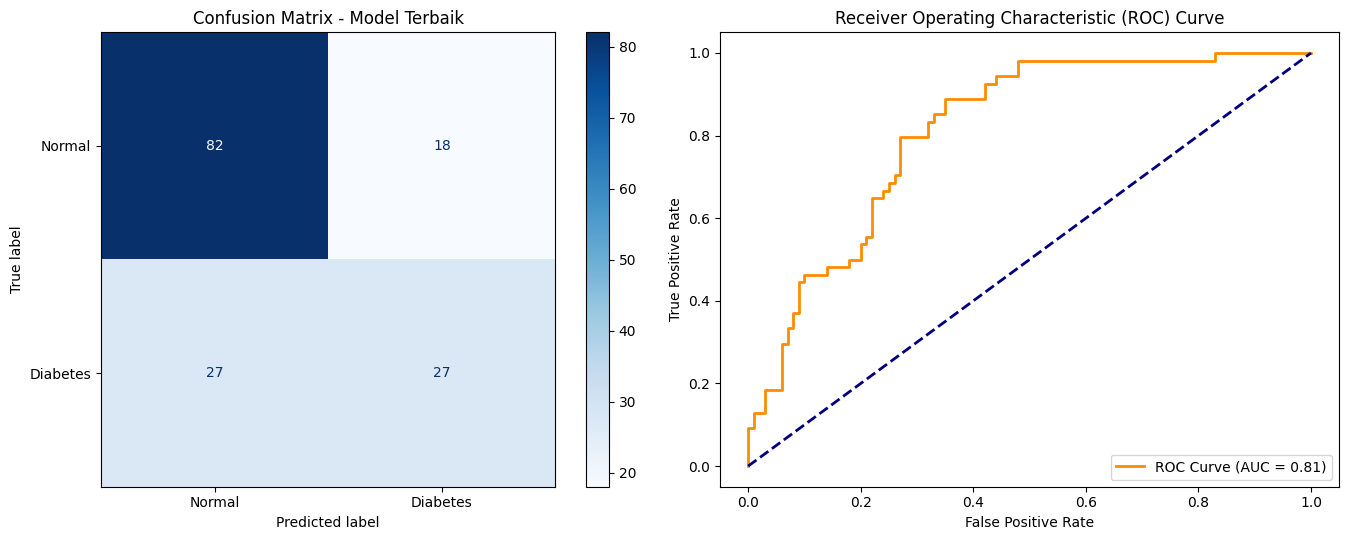

In [ ]:
# Tuning Hyperparameter untuk Model Terbaik (Logistic Regression)
param_grid = {
    "logisticregression__C": [0.01, 0.1, 1, 10, 100]
}
gs = GridSearchCV(models["LogReg"], param_grid, cv=cv, scoring="f1", n_jobs=-1)
gs.fit(X_train, y_train)
best_model = gs.best_estimator_

print("=== Hasil Tuning Hyperparameter ===")
print("Parameter Terbaik:", gs.best_params_)
print("F1-Score Train:", round(gs.best_score_, 3))

# Prediksi pada Data Test
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

print("\n=== Classification Report (Test Set) ===")
print(classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix & ROC Curve Berdampingan
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=['Normal', 'Diabetes'], cmap="Blues", ax=ax[0])
ax[0].set_title("Confusion Matrix - Model Terbaik")

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)
ax[1].plot(fpr, tpr, color="darkorange", lw=2, label=f"ROC Curve (AUC = {roc_auc:.2f})")
ax[1].plot([0, 1], [0, 1], color="navy", lw=2, linestyle="--")
ax[1].set_xlabel("False Positive Rate")
ax[1].set_ylabel("True Positive Rate")
ax[1].set_title("Receiver Operating Characteristic (ROC) Curve")
ax[1].legend(loc="lower right")

plt.tight_layout()
plt.show()

### 4. Unsupervised Learning (PCA & K-Means)

=== Hasil Evaluasi Unsupervised ===
Silhouette Score:  0.196
ARI (Adjusted Rand Index) vs Label Asli: 0.161


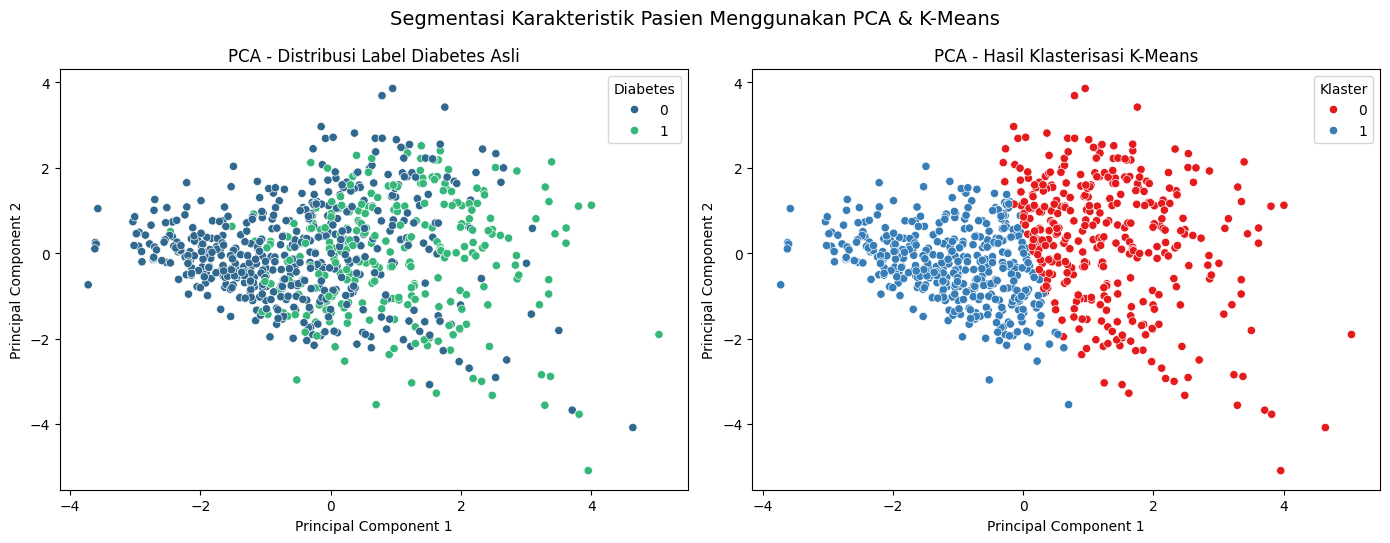

In [ ]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Preprocessing data secara independen tanpa target label
preprocessor_unsupervised = make_pipeline(
    ClinicalZeroReplacer(clinical_cols),
    SimpleImputer(strategy="median"),
    StandardScaler()
)
Xs = preprocessor_unsupervised.fit_transform(X_raw)

# Reduksi Dimensi menggunakan PCA 2-Komponen
pca_obj = PCA(n_components=2, random_state=42)
X_pca = pca_obj.fit_transform(Xs)

# K-Means Clustering
kmeans = KMeans(n_clusters=2, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(Xs)

print("=== Hasil Evaluasi Unsupervised ===")
print("Silhouette Score: ", round(silhouette_score(Xs, cluster_labels), 3))
print("ARI (Adjusted Rand Index) vs Label Asli:", round(adjusted_rand_score(y_raw, cluster_labels), 3))

# Visualisasi 1x2 Berdampingan (Label Diabetes Asli vs Hasil Klaster K-Means)
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))

# Kiri: True Label
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_raw.values, palette="viridis", ax=ax[0])
ax[0].set_title("PCA - Distribusi Label Diabetes Asli")
ax[0].set_xlabel("Principal Component 1")
ax[0].set_ylabel("Principal Component 2")
ax[0].legend(title="Diabetes")

# Kanan: K-Means Clusters
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=cluster_labels, palette="Set1", ax=ax[1])
ax[1].set_title("PCA - Hasil Klasterisasi K-Means")
ax[1].set_xlabel("Principal Component 1")
ax[1].set_ylabel("Principal Component 2")
ax[1].legend(title="Klaster")

plt.suptitle("Segmentasi Karakteristik Pasien Menggunakan PCA & K-Means", fontsize=14, y=0.98)
plt.tight_layout()
plt.show()